Engine Online: 30,063 sessions loaded.

   NEUROLINK 2.0 PERFORMANCE REPORT   
Consistency (Volatility)  | 6.92 WPM
Error Penalty (Recovery)  | -4.70 WPM/error
Best Perfect Streak       | 5 Sessions

Ghost Prediction: 5.04 seconds
--- SPECTRE 2.0: ADVANCED TELEMETRY ONLINE ---
Analyzing 30,063 total sessions.


/tmp/ipython-input-136908326.py:131: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='hour', y='wpm', data=self.df, ax=axes[0, 1], palette='viridis', fliersize=0)


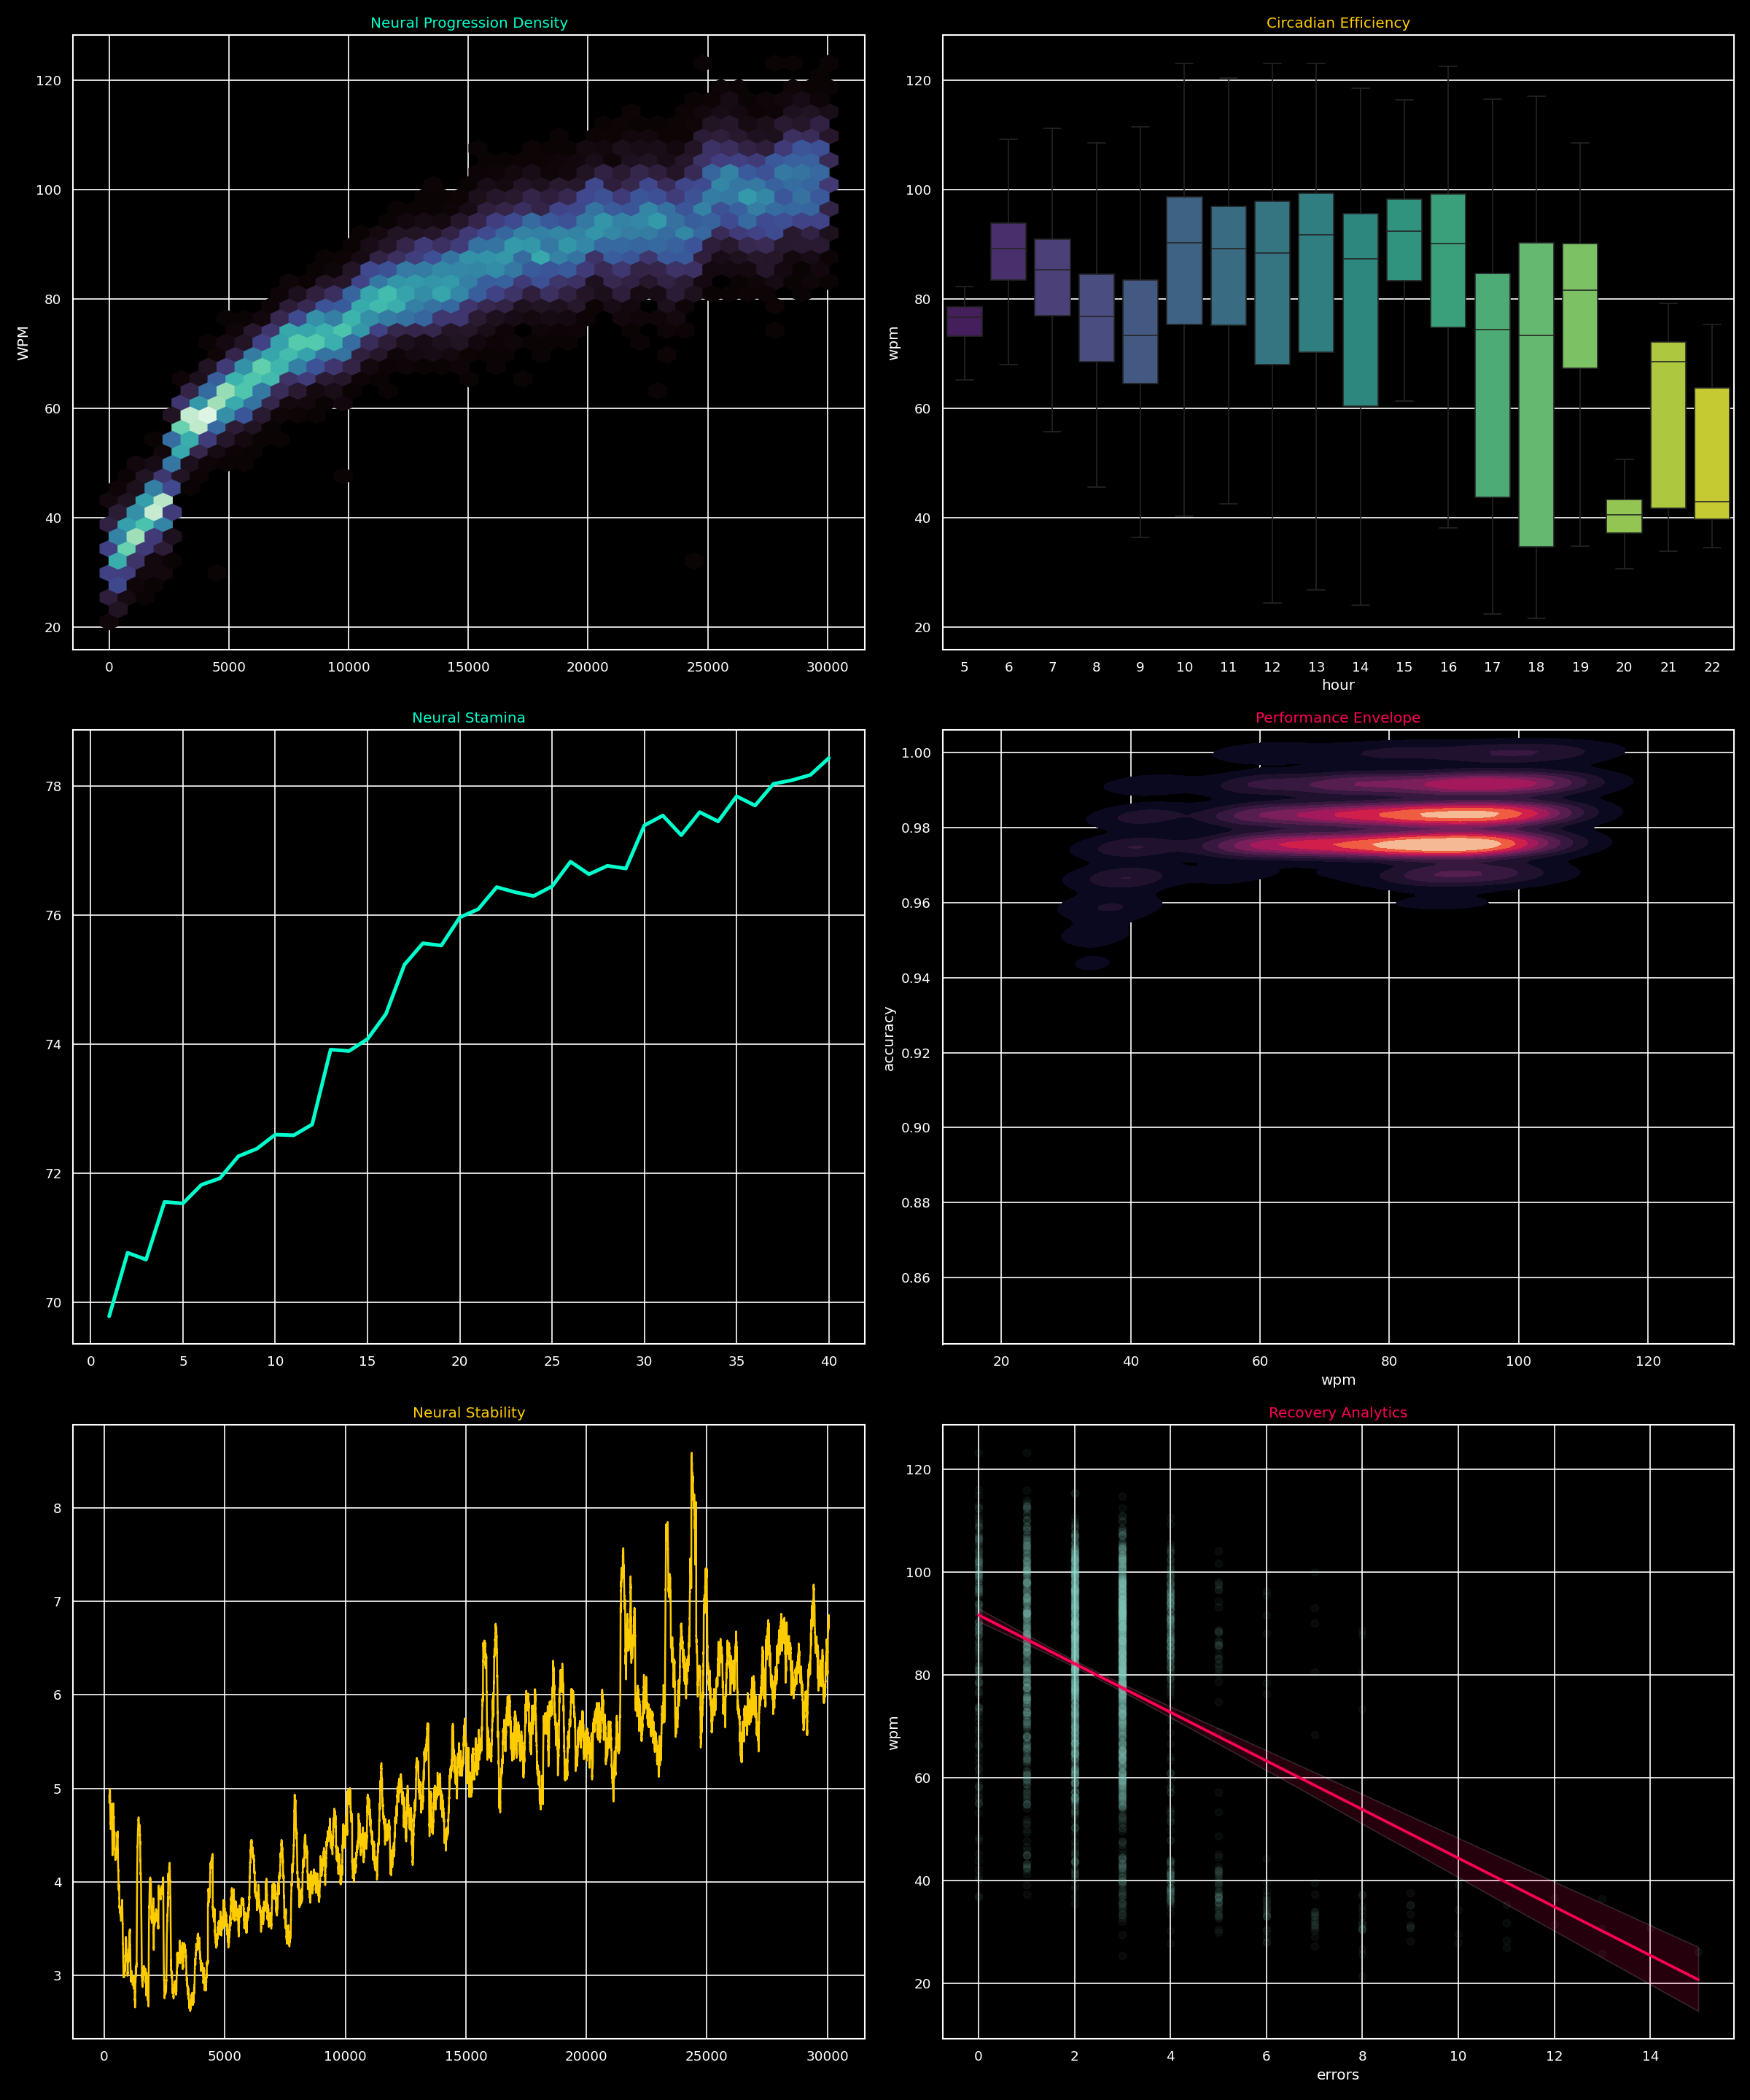

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import os
from IPython.display import Image, display

# =============================
# NEUROLINK ENGINE (MERGED + FIXED)
# =============================
class NeuroLinkEngine:
    """
    NeuroLink 2.0: Advanced Human-Computer Interaction Analysis Engine.
    Processes large-scale typing sessions to extract performance metrics.
    """
    def __init__(self, csv_path):
        self.csv_path = csv_path
        self.df = None
        self.load_data()

    def load_data(self):
        if not os.path.exists(self.csv_path):
            print(f"Error: {self.csv_path} not found.")
            return
        self.df = pd.read_csv(self.csv_path)
        self.df['timestamp'] = pd.to_datetime(self.df['timestamp'])
        self.df = self.df.sort_values('timestamp').reset_index(drop=True)
        self.df['session_id'] = self.df.index + 1
        print(f"Engine Online: {len(self.df):,} sessions loaded.")

    # --- Ghost Simulator Core ---

    def generate_practice_text(self, length=40):
        """Generate a random practice sentence for Ghost simulation."""
        words = [
            "the", "quick", "brown", "fox", "jumps", "over", "lazy", "dog",
            "neural", "typing", "performance", "analysis", "speed", "accuracy",
            "practice", "focus", "consistency", "control"
        ]
        text = []
        while len(" ".join(text)) < length:
            text.append(np.random.choice(words))
        return " ".join(text).strip().capitalize() + "."


    def get_neural_metrics(self):
        avg_wpm = self.df['wpm'].tail(500).mean()
        z = np.polyfit(self.df['errors'], self.df['wpm'], 1)
        error_penalty = abs(z[0])
        return avg_wpm, error_penalty

    def predict_ghost_time(self, text):
        avg_wpm, penalty = self.get_neural_metrics()
        chars_per_sec = (avg_wpm * 5) / 60
        base_time = len(text) / chars_per_sec
        simulated_errors = round(len(text) * 0.01)
        lost_time = simulated_errors * (penalty / 10)
        return round(base_time + lost_time, 2)

    # --- Mastery Matrix ---
    def get_mastery_matrix(self):
        volatility = self.df['wpm'].rolling(window=100).std().iloc[-1]
        z = np.polyfit(self.df['errors'], self.df['wpm'], 1)
        penalty = abs(z[0])

        self.df['is_perfect'] = self.df['accuracy'] == 1.0
        self.df['streak'] = (
            self.df['is_perfect']
            .groupby((self.df['is_perfect'] != self.df['is_perfect'].shift()).cumsum())
            .cumcount() + 1
        )
        self.df.loc[~self.df['is_perfect'], 'streak'] = 0
        max_streak = self.df['streak'].max()

        return {
            "Consistency (Volatility)": f"{volatility:.2f} WPM",
            "Error Penalty (Recovery)": f"-{penalty:.2f} WPM/error",
            "Best Perfect Streak": f"{max_streak} Sessions"
        }

    def generate_report(self):
        metrics = self.get_mastery_matrix()
        print("\n" + "=" * 40)
        print("   NEUROLINK 2.0 PERFORMANCE REPORT   ")
        print("=" * 40)
        for k, v in metrics.items():
            print(f"{k:25} | {v}")
        print("=" * 40 + "\n")

# =============================
# SPECTRE ENGINE (UNCHANGED LOGIC, FIXED SYNTAX ONLY)
# =============================
class SpectreEngine:
    def __init__(self, csv_path='cleaned_typing_data_v30k.csv'):
        self.csv_path = csv_path
        if not os.path.exists(csv_path):
            raise FileNotFoundError(f"Missing {csv_path}!")

        self.df = pd.read_csv(csv_path)
        self.df['timestamp'] = pd.to_datetime(self.df['timestamp'])
        self.df = self.df.sort_values('timestamp').reset_index(drop=True)

        self.df['wpm'] = self.df['speed'] / 5
        self.df['session_id'] = self.df.index + 1
        self.df['hour'] = self.df['timestamp'].dt.hour
        self.df['date'] = self.df['timestamp'].dt.date
        self.df['session_of_day'] = self.df.groupby('date').cumcount() + 1

        print("--- SPECTRE 2.0: ADVANCED TELEMETRY ONLINE ---")
        print(f"Analyzing {len(self.df):,} total sessions.")

    def save_dashboard(self, output_name='spectre_v2_advanced.png'):
        plt.style.use('dark_background')
        fig, axes = plt.subplots(3, 2, figsize=(20, 24))

        c_cyan, c_magenta, c_yellow = '#00ffcc', '#ff0055', '#ffcc00'

        axes[0, 0].hexbin(self.df['session_id'], self.df['wpm'], gridsize=40, cmap='mako', mincnt=1)
        axes[0, 0].set_title('Neural Progression Density', color=c_cyan)
        axes[0, 0].set_ylabel('WPM')

        sns.boxplot(x='hour', y='wpm', data=self.df, ax=axes[0, 1], palette='viridis', fliersize=0)
        axes[0, 1].set_title('Circadian Efficiency', color=c_yellow)

        fatigue = self.df[self.df['session_of_day'] <= 40].groupby('session_of_day')['wpm'].mean()
        axes[1, 0].plot(fatigue.index, fatigue.values, color=c_cyan, linewidth=3)
        axes[1, 0].set_title('Neural Stamina', color=c_cyan)

        sns.kdeplot(x=self.df['wpm'], y=self.df['accuracy'], ax=axes[1, 1], cmap="rocket", fill=True, thresh=0.05)
        axes[1, 1].set_title('Performance Envelope', color=c_magenta)

        volatility = self.df['wpm'].rolling(window=200).std()
        axes[2, 0].plot(self.df['session_id'], volatility, color=c_yellow)
        axes[2, 0].set_title('Neural Stability', color=c_yellow)

        sns.regplot(
            data=self.df.sample(min(3000, len(self.df))),
            x='errors', y='wpm', ax=axes[2, 1],
            scatter_kws={'alpha': 0.05}, line_kws={'color': c_magenta}
        )
        axes[2, 1].set_title('Recovery Analytics', color=c_magenta)

        plt.tight_layout()
        plt.savefig(output_name, dpi=120)
        plt.close()
        display(Image(output_name))

# =============================
# MAIN EXECUTION
# =============================
if __name__ == "__main__":
    engine = NeuroLinkEngine('cleaned_typing_data_v30k.csv')
    engine.generate_report()

    test_text = engine.generate_practice_text()
    prediction = engine.predict_ghost_time(test_text)
    print(f"Ghost Prediction: {prediction} seconds")

    spectre = SpectreEngine('cleaned_typing_data_v30k.csv')
    spectre.save_dashboard()


In [6]:
import pandas as pd
import numpy as np
import os

class NeuroLinkEngine:
    def __init__(self, csv_path):
        self.csv_path = csv_path
        self.df = None
        self.load_data()

    def load_data(self):
        if not os.path.exists(self.csv_path):
            print(f"Error: {self.csv_path} not found.")
            return
        self.df = pd.read_csv(self.csv_path)
        self.df['timestamp'] = pd.to_datetime(self.df['timestamp'])
        self.df = self.df.sort_values('timestamp').reset_index(drop=True)
        print(f"Engine Online: {len(self.df)} sessions loaded.")

    def get_neural_metrics(self):
        """Extracts the 'DNA' for the Ghost simulation."""
        avg_wpm = self.df['wpm'].tail(500).mean()  # Recent speed
        z = np.polyfit(self.df['errors'], self.df['wpm'], 1)
        error_penalty = abs(z[0])
        return avg_wpm, error_penalty

    def predict_ghost_time(self, text):
        """
        THE GHOST SIMULATOR
        Predicts how long YOU would take to type a specific text.
        """
        avg_wpm, penalty = self.get_neural_metrics()

        # Convert WPM to characters per second
        chars_per_sec = (avg_wpm * 5) / 60
        base_time = len(text) / chars_per_sec

        # Simulate a 1% chance of error per character
        simulated_errors = round(len(text) * 0.01)

        # Apply personal error penalty (converted to seconds)
        lost_time = simulated_errors * (penalty / 10)

        total_predicted_time = base_time + lost_time
        return round(total_predicted_time, 2)

    def generate_practice_text(self, length=45):
        """Generates a practice sentence for Ghost simulation."""
        words = [
            "the", "quick", "brown", "fox", "jumps", "over", "lazy", "dog",
            "typing", "speed", "accuracy", "focus", "control",
            "performance", "practice", "consistency"
        ]

        sentence = []
        while len(" ".join(sentence)) < length:
            sentence.append(np.random.choice(words))

        return " ".join(sentence).capitalize() + "."

# =========================
# MAIN EXECUTION
# =========================
if __name__ == "__main__":
    engine = NeuroLinkEngine('cleaned_typing_data_v30k.csv')

    # Generated practice sentence
    test_text = engine.generate_practice_text()

    prediction = engine.predict_ghost_time(test_text)

    print("\n" + "=" * 40)
    print("   NEUROLINK 2.0: GHOST PREDICTION   ")
    print("=" * 40)
    print(f"Input Text : '{test_text}'")
    print(f"Ghost Time : {prediction} seconds")
    print(f"Logic      : Based on your last 30,000 sessions.")
    print("=" * 40 + "\n")


Engine Online: 30063 sessions loaded.

   NEUROLINK 2.0: GHOST PREDICTION   
Input Text : 'Speed practice over over control typing jumps.'
Ghost Time : 5.39 seconds
Logic      : Based on your last 30,000 sessions.

